In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras.datasets import imdb, boston_housing
import pickle
from keras import layers, models, optimizers, losses, metrics, regularizers, callbacks

I0000 00:00:1792495233.171934  372092 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792495233.175078  372092 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792495233.613419  372092 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792495234.673973  372092 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [5]:
keras.utils.set_random_seed(67)

In [6]:
histories = {}

In [7]:
import os
# we reload the saved histories if they exist, so that a crash or a rerun never wipes our results
histories = pickle.load(open("histories.pkl", "rb")) if os.path.exists("histories.pkl") else {}
print(histories.keys())  # we expect original, smaller and bigger

dict_keys(['original', 'smaller', 'bigger'])


In [4]:
(x_tr, y_tr), _ = boston_housing.load_data()
x_tr.shape

(404, 13)

# Part 1 - IMDB Classification (Sentiment Analysis)

### 1 - Loading the IMDB dataset

In [8]:
# Question 1 : 
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)
print(f"Number of train examples : {train_data.shape[0]}, Number of test examples : {test_data.shape[0]}\n")
print(f"Type of train_data : {type(train_data)}")
print(f"First 10 words indices of the first training example (along with label) : {train_data[0][:10]}, {train_labels[0]}")
print(f"Length of the first training example : {len(train_data[0])}")

# A raw review is a list of words. Theses words are encoded as integers, where each integer represents a specific word in a dictionary. 
# (The dictionary only includes the 10,000 most frequently occurring words in the dataset)
# Then, a vector of 10,000 dimensions is created for each review. 
# Each dimension of the vector corresponds to a specific word (out of the 10000 most frequent) in the dictionary. 

Number of train examples : 25000, Number of test examples : 25000

Type of train_data : <class 'numpy.ndarray'>
First 10 words indices of the first training example (along with label) : [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65], 1
Length of the first training example : 218


### 2 - Vectorizing the data

In [9]:
# Question 2 :
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype=np.float32)
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results

In [10]:
# Question 3 : 
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")
print(train_data)
print(x_train)

[list([1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32])
 list([1, 194, 1153, 194, 8255, 78, 228, 5, 6, 1463, 

In [8]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)
print(x_train[0][:20])
# we compare two independent computations: if they match, the vectorization is correct
print(f"unique words: {x_train[0].sum()}")

(25000, 10000) (25000, 10000) (25000,) (25000,)
[0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1.]
unique words: 120.0


### 3 - Effect of model size

In [9]:
# Question 4 :

original_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
    ])
original_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
original_model.summary()

E0000 00:00:1792493778.865408  190603 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Question 5 : 

smaller_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid")
    ])
smaller_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
smaller_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 4)              │        40,004 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,029 (156.36 KB)

 Trainable params: 40,029 (156.36 KB)

 Non-trainable params: 0 (0.00 B)

Total params for original_model > 160.305
Total params for smaller_model > 40.029 
Question4 model has approx. 4 times more params than question5 one, heavely weighed on by the first dense layer.  

In [11]:
# Question 6 : 
history_original = original_model.fit(x_train, y_train, epochs=20, batch_size=512, validation_data=(x_test, y_test))
histories["original"] = history_original.history
history_smaller = smaller_model.fit(x_train, y_train, epochs=20, batch_size=512, validation_data=(x_test, y_test))
histories["smaller"] = history_smaller.history

pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - acc: 0.8190 - loss: 0.4717 - val_acc: 0.8738 - val_loss: 0.3546
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9031 - loss: 0.2809 - val_acc: 0.8882 - val_loss: 0.2906
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - acc: 0.9208 - loss: 0.2200 - val_acc: 0.8899 - val_loss: 0.2772
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9336 - loss: 0.1882 - val_acc: 0.8855 - val_loss: 0.2874
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9426 - loss: 0.1642 - val_acc: 0.8824 - val_loss: 0.2976
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9488 - loss: 0.1472 - val_acc: 0.8768 - val_loss: 0.3217
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9547 - loss: 0.1331 - val_acc: 0.8779 - val_loss: 0.3282
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - acc: 0.9585 - loss: 0.1212 - val_acc: 0.8746 - val_loss: 0.3439
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - acc: 0.9641

In [11]:
def plot_curves(histories, names, key="val_loss"):
    plt.figure(figsize=(12, 8))
    for name in names:
        values = histories[name][key]
        epochs = range(1, len(values) + 1)
        plt.plot(epochs, values, label=name)
    plt.xlabel("Epochs")
    plt.ylabel(key)
    plt.legend()
    plt.show()

def best_epoch(histories, key="val_loss"):
    values = histories[key]
    i = int(np.argmin(values))
    return i+1, values[i]

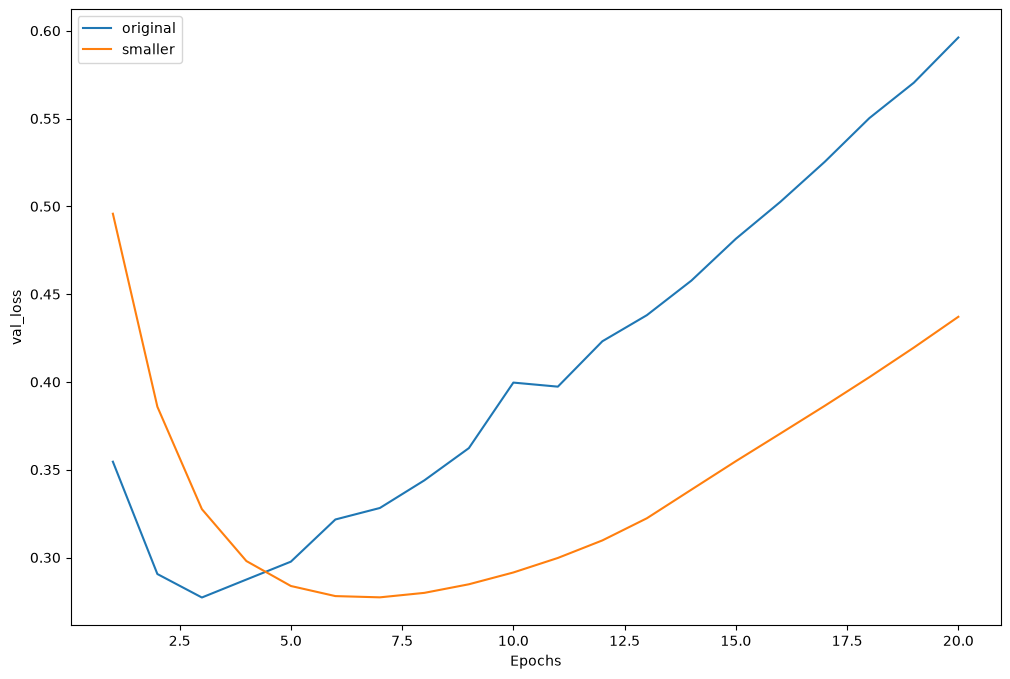

In [13]:
# Question 7 :

plot_curves(histories, ["original", "smaller"], key="val_loss")

In [14]:
for name in ["original", "smaller"]:
    ep, val = best_epoch(histories[name])
    print(f"{name}: min val_loss = {val:.4f} at epoch {ep}")

original: min val_loss = 0.2772 at epoch 3
smaller: min val_loss = 0.2773 at epoch 7


Original reaches its minimum validation loss at epoch 3 (0.2772), smaller at epoch 7 (0.2773). Both minima are almost identical, and both models overfit afterwards: the validation loss rises while the training loss keeps decreasing. Original overfits during the 17 remaining epochs, and much faster: its validation loss climbs from 0.28 to 0.60, against 0.28 to 0.44 for smaller. With 4 times fewer parameters, smaller has a lower capacity, so it learns more slowly and memorizes the training set more slowly. Since both reach the same best loss, the extra capacity of original brings no gain on this problem, only a faster overfitting.

In [15]:
# Question 8 :

bigger_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(512, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(1, activation="sigmoid")
    ])
bigger_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
bigger_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 512)            │     5,120,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,383,681 (20.54 MB)

 Trainable params: 5,383,681 (20.54 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history_bigger = bigger_model.fit(x_train, y_train, epochs=20, batch_size=512,
                                  validation_data=(x_test, y_test))
histories["bigger"] = history_bigger.history
pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - acc: 0.7678 - loss: 0.4929 - val_acc: 0.7829 - val_loss: 0.4716
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - acc: 0.8889 - loss: 0.2747 - val_acc: 0.7594 - val_loss: 0.6341
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - acc: 0.9089 - loss: 0.2315 - val_acc: 0.8893 - val_loss: 0.2687
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - acc: 0.9315 - loss: 0.1745 - val_acc: 0.8792 - val_loss: 0.2895
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - acc: 0.9472 - loss: 0.1380 - val_acc: 0.8763 - val_loss: 0.3323
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - acc: 0.9592 - loss: 0.1037 - val_acc: 0.8816 - val_loss: 0.3342
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - acc: 0.9762 - loss: 0.0708 - val_acc: 0.8817 - val_loss: 0.3963
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - acc: 0.9888 - loss: 0.0392 - val_acc: 0.8018 - val_loss: 0.8993
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - acc: 0.9826

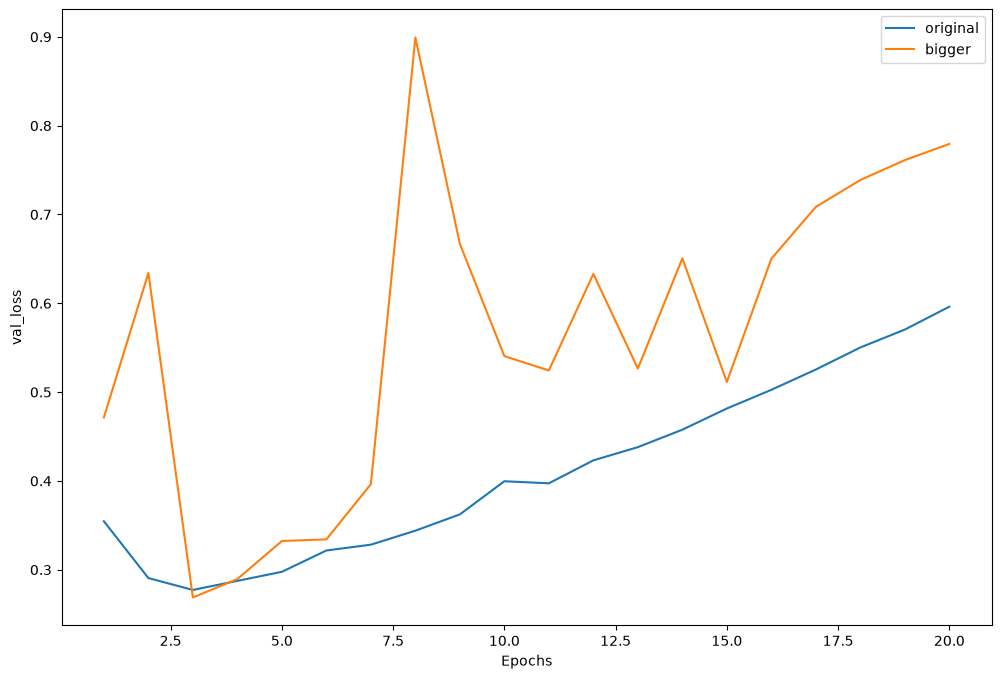

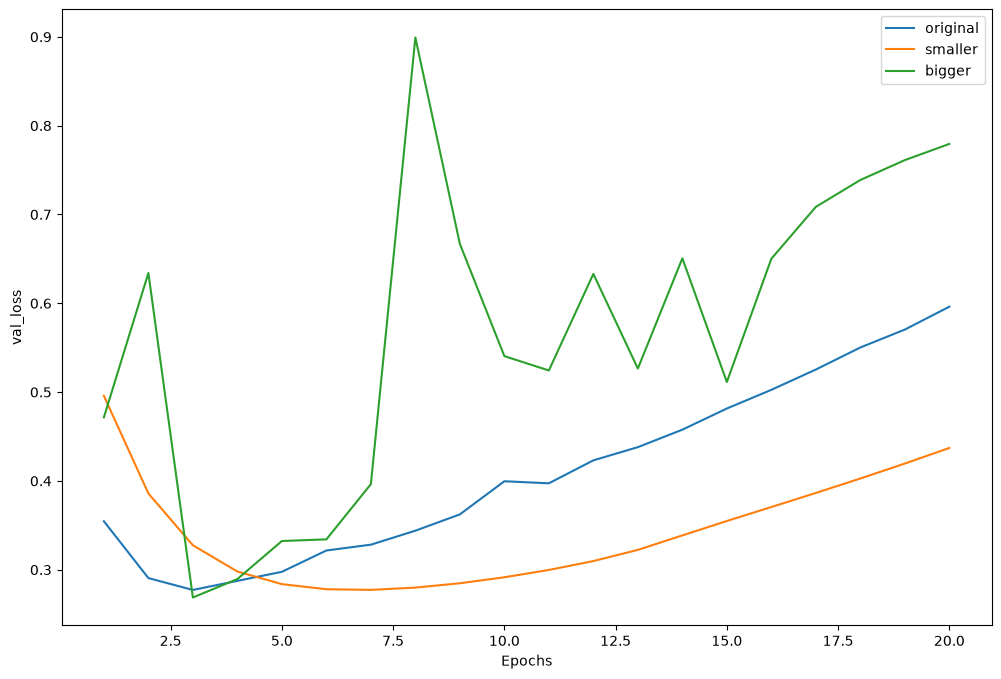

In [28]:
# Question 9 :
plot_curves(histories, ["original", "bigger"])
plot_curves(histories, ["original", "smaller", "bigger"], key="val_loss")

In [29]:
for name in ["smaller", "original", "bigger"]:
    ep, val = best_epoch(histories[name])
    print(f"{name}: min val_loss = {val:.4f} at epoch {ep}")

smaller: min val_loss = 0.2773 at epoch 7
original: min val_loss = 0.2772 at epoch 3
bigger: min val_loss = 0.2687 at epoch 3


All three models are able to reach almost the same validation score, around 0.27/0.28. 
We also notice that the validation loss tends to grows higher later in the training (after the minimum is reached) if the capacity is higher.
We can then conclude that : 
- The additional computation required by original and bigger models then aren't necessary.
- A bigger capacity makes the model really prone to overfitting

### L2 regularization (weight decay)

In [12]:
# Question 10 : 
l2_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(1, activation="sigmoid")
    ])
l2_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
l2_model.summary()

E0000 00:00:1792495286.667380  372092 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

The principle of the L2 penalty is to penalize large weights in our training. It adds to the loss func the sum of the squared weights (multiplied by the penalty parameter lambda). The goal is to help the model generalize better rather than overfitting.

In [13]:
# Question 11 : 
history_l2 = l2_model.fit(x_train, y_train, epochs=20, batch_size=512,
                          validation_data=(x_test, y_test))
histories["l2"] = history_l2.history
pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - acc: 0.8187 - loss: 0.5183 - val_acc: 0.8740 - val_loss: 0.4023
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9002 - loss: 0.3348 - val_acc: 0.8857 - val_loss: 0.3447
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9160 - loss: 0.2824 - val_acc: 0.8881 - val_loss: 0.3304
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9250 - loss: 0.2589 - val_acc: 0.8877 - val_loss: 0.3312
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9318 - loss: 0.2417 - val_acc: 0.8615 - val_loss: 0.3971
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9353 - loss: 0.2355 - val_acc: 0.8834 - val_loss: 0.3445
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9413 - loss: 0.2237 - val_acc: 0.8595 - val_loss: 0.4183
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9415 - loss: 0.2217 - val_acc: 0.8724 - val_loss: 0.3777
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9432 - loss:

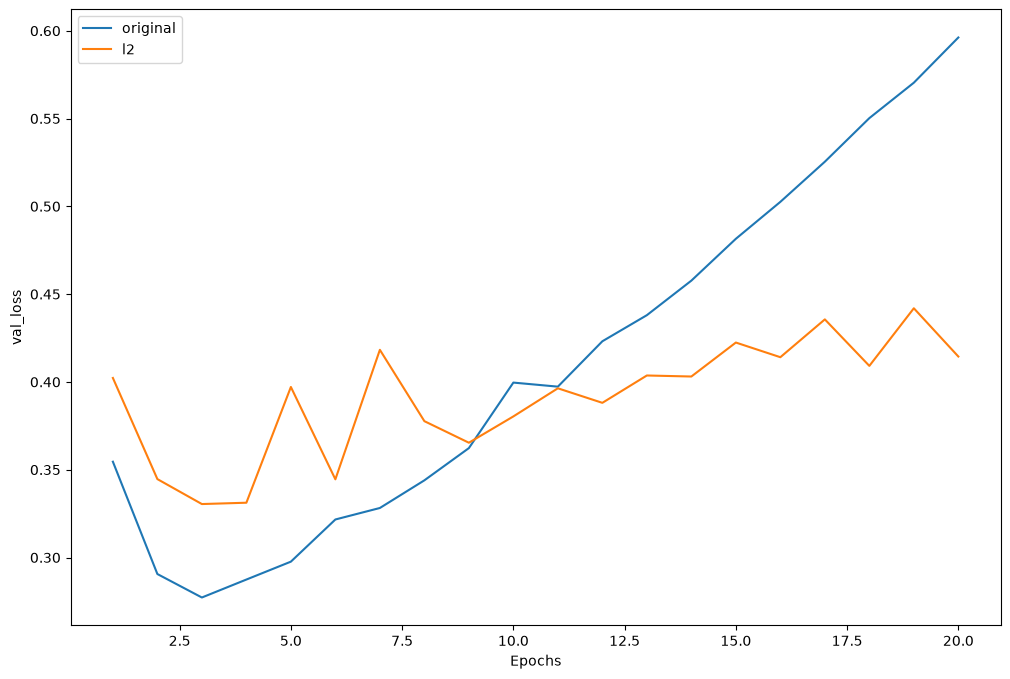

In [14]:
# Question 12 : 
plot_curves(histories, ["original", "l2"])

Both models have exactly the same number of parameters (160,305), but the L2 penalty constrains the values of the weights, which reduces the effective capacity of the model: it cannot rely on a few very large weights to memorize the training set. This is visible on the training metrics (train accuracy around 0.955 vs 0.98 for original). As a consequence, after its minimum the validation loss of l2 rises much more slowly than that of original. Its minimum validation loss is higher, but this value includes the penalty term itself; the validation accuracies at their best epoch are comparable. L2 does not improve the best score here, but makes the model much more robust to overfitting

### Bonus Question - L1 and L1 + L2 regularization

In [15]:
# Question 13 :
l1_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l1(0.001)),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l1(0.001)),
    layers.Dense(1, activation="sigmoid")
    ])
l1_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])

l1_l2_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l1_l2(l1=0.001, l2=0.001)),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l1_l2(l1=0.001, l2=0.001)),
    layers.Dense(1, activation="sigmoid")
    ])
l1_l2_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])

In [16]:
history_l1 = l1_model.fit(x_train, y_train, epochs=20, batch_size=512,
                          validation_data=(x_test, y_test))
histories["l1"] = history_l1.history
history_l1_l2 = l1_l2_model.fit(x_train, y_train, epochs=20, batch_size=512,
                                validation_data=(x_test, y_test))
histories["l1_l2"] = history_l1_l2.history
pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.7724 - loss: 0.9640 - val_acc: 0.8441 - val_loss: 0.6616
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.8466 - loss: 0.6262 - val_acc: 0.8453 - val_loss: 0.6113
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.8545 - loss: 0.5849 - val_acc: 0.8485 - val_loss: 0.5905
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.8587 - loss: 0.5647 - val_acc: 0.8504 - val_loss: 0.5783
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8606 - loss: 0.5521 - val_acc: 0.8517 - val_loss: 0.5687
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8624 - loss: 0.5416 - val_acc: 0.8565 - val_loss: 0.5568
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.8657 - loss: 0.5327 - val_acc: 0.8563 - val_loss: 0.5531
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8685 - loss: 0.5255 - val_acc: 0.8563 - val_loss: 0.5491
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8700 - loss:

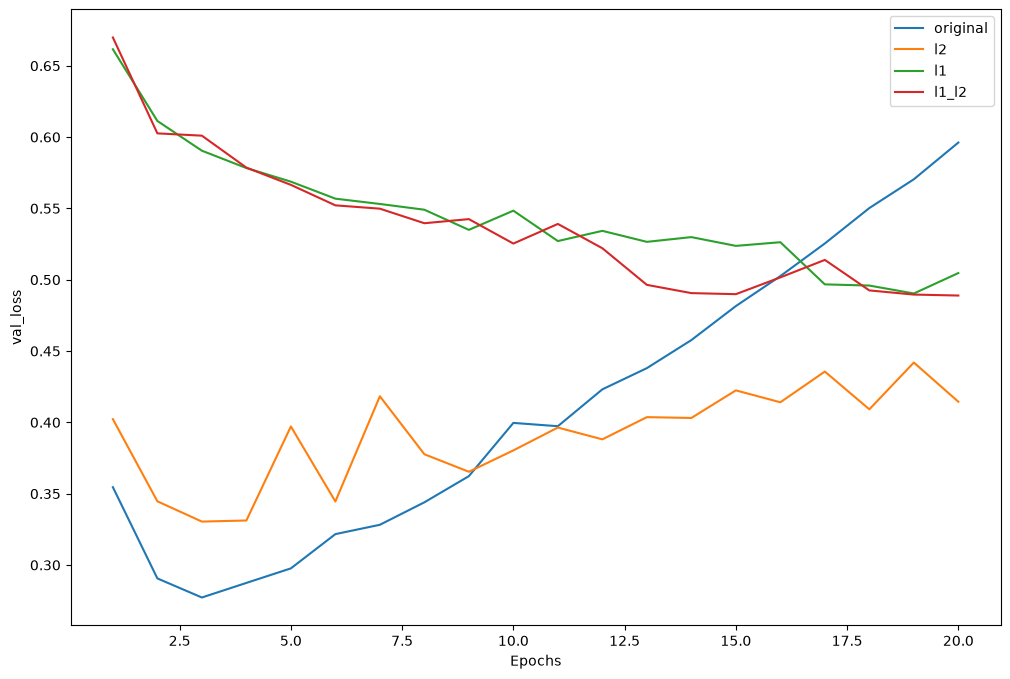

original: min val_loss = 0.2772 at epoch 3
l2: min val_loss = 0.3304 at epoch 3
l1: min val_loss = 0.4903 at epoch 19
l1_l2: min val_loss = 0.4889 at epoch 20
l2: 11.8% of weights are almost zero
l1: 88.0% of weights are almost zero
l1_l2: 89.9% of weights are almost zero


In [18]:
plot_curves(histories, ["original", "l2", "l1", "l1_l2"])
for name in ["original", "l2", "l1", "l1_l2"]:
    ep, val = best_epoch(histories[name])
    print(f"{name}: min val_loss = {val:.4f} at epoch {ep}")

# we measure sparsity : the share of first layer weights that are almost zero
for name, model in [("l2", l2_model), ("l1", l1_model), ("l1_l2", l1_l2_model)]:
    w = model.layers[0].get_weights()[0]  # kernel of the first dense layer, shape (10000, 16)
    print(f"{name}: {np.mean(np.abs(w) < 0.001) * 100:.1f}% of weights are almost zero")

Unlike original and l2, l1 and l1_l2 do not overfit within 20 epochs : their validation loss keeps decreasing until the last epochs (minimum of 0.4903 at epoch 19 for l1, 0.4889 at epoch 20 for l1_l2). However, it stays much higher than the others (around 0.49, against 0.28 for original and 0.33 for l2). This is partly because the L1 penalty, which is lambda multiplied by the sum of |w| over the 160,000 weights, is included in the displayed loss. Such a strong penalty also seems to slow down the learning : the model fits the training data more slowly.

The difference between L1 and L2 comes from the gradient of the penalty :
- L2 penalizes w^2, so its gradient (2 * lambda * w) gets smaller as the weight gets smaller : weights are pushed toward 0 but almost never reach it. All weights stay small but non-zero.
- L1 penalizes |w|, so its gradient (lambda * sign(w)) has the same strength whatever the size of the weight : even tiny weights are pushed until they reach 0. Many weights become (almost) zero : the weights are sparse.

With 10,000 input words, L1 then acts like a feature selection : the model only keeps the words that really help predict the sentiment. We can check it on the first layer : 88.0% of the weights are almost zero (absolute value below 0.001) for l1 and 89.9% for l1_l2, against only 11.8% for l2.

### 5 - Dropout

In [19]:
# Question 14 :
dropout_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
    ])
dropout_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
dropout_model.summary()

# Dropout helps to reduce overfitting by randomly setting a fraction of input units to 0 at each update during training time, which helps prevent the model from becoming too reliant on any one feature. 
# It encourages the network to learn more robust features that make the model more generalizable.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Question 15 : 
dropout_history = dropout_model.fit(x_train, y_train, epochs=20, batch_size=512,
                                    validation_data=(x_test, y_test))
histories["dropout"] = dropout_history.history
pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - acc: 0.6640 - loss: 0.6104 - val_acc: 0.8582 - val_loss: 0.4850
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8088 - loss: 0.4690 - val_acc: 0.8789 - val_loss: 0.3658
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8682 - loss: 0.3757 - val_acc: 0.8845 - val_loss: 0.3099
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8960 - loss: 0.3208 - val_acc: 0.8889 - val_loss: 0.2892
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9120 - loss: 0.2839 - val_acc: 0.8866 - val_loss: 0.2835
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9234 - loss: 0.2483 - val_acc: 0.8879 - val_loss: 0.2853
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9310 - loss: 0.2227 - val_acc: 0.8859 - val_loss: 0.3001
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9375 - loss: 0.1971 - val_acc: 0.8849 - val_loss: 0.3115
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9450 - loss:

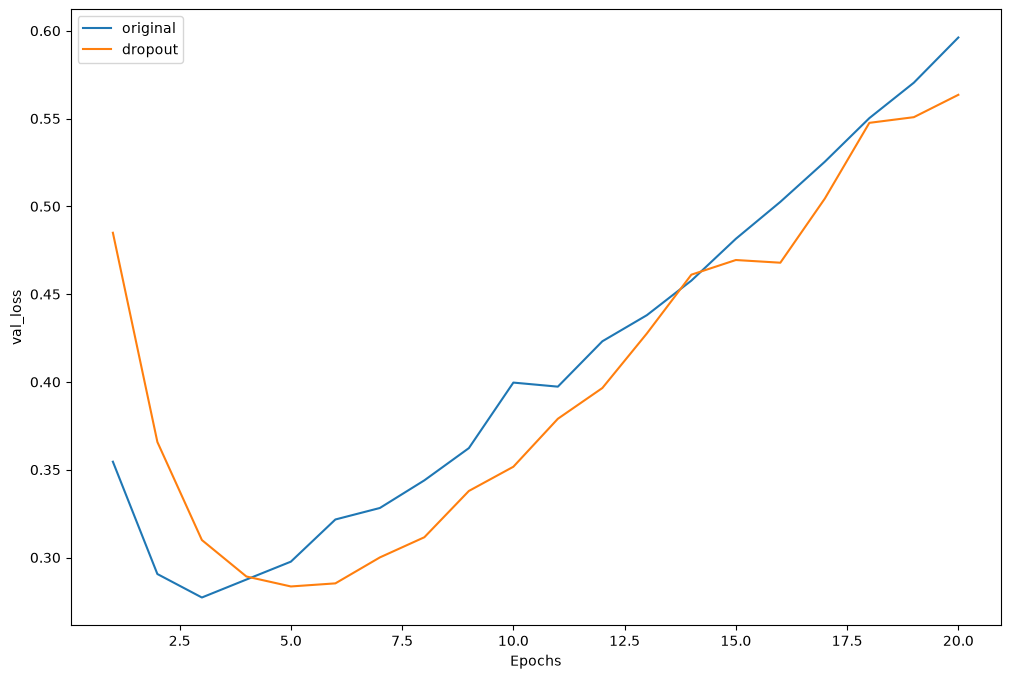

original: min val_loss = 0.2772 at epoch 3
dropout: min val_loss = 0.2835 at epoch 5


In [22]:
# Question 16 : 
plot_curves(histories, ["original", "dropout"])
for name in ["original", "dropout"]:
    ep, val = best_epoch(histories[name])
    print(f"{name}: min val_loss = {val:.4f} at epoch {ep}")

We see that dropout reaches its minimum validation loss later than original (epoch 5 vs epoch 3), with almost the same value (0.2835 vs 0.2772). After its minimum, the validation loss of dropout still rises, but slightly more slowly : it reaches 0.56 at epoch 20, against 0.60 for original. The training accuracy still goes up to 0.97, which shows that the model keeps memorizing the training set, only more slowly.

We also notice that during the first epochs (1 to 4), the training loss of dropout is higher than its validation loss (0.61 vs 0.49 at epoch 1). This is because the training loss is computed with half of the hidden units turned off, while dropout is disabled when the model is evaluated on the validation set.

We can then conclude that :
- Dropout delays overfitting and slows it down a bit, but does not prevent it : on 20 epochs, it is less effective than L2 here (final validation loss of 0.41 for l2 vs 0.56 for dropout).
- It is most useful in combination with a way to stop training near the minimum, like early stopping.

### 6 - Bonus question, Text data augmentation

In [60]:
# Question 17 :
def augment_sequence(sequence, drop_prob=0.10, unk_prob=0.10, min_len=8):
    augmented = []
    for word in sequence:
        r = np.random.rand()  # one uniform draw in [0, 1) decides what happens to this word
        if r < drop_prob:
            continue  # the word is dropped
        elif r < drop_prob + unk_prob:
            augmented.append(2)  # index 2 is the <UNK> token in the keras imdb encoding
        else:
            augmented.append(word)  # the word is kept
    if len(augmented) < min_len:
        return list(sequence[:min_len])
    return augmented

In [61]:
# we check the length and the number of <UNK> tokens before and after augmentation
aug = augment_sequence(train_data[0])
print(f"length : {len(train_data[0])} -> {len(aug)}")
print(f"<UNK> count : {list(train_data[0]).count(2)} -> {aug.count(2)}")

length : 218 -> 200
<UNK> count : 6 -> 16


In [62]:
# Question 18 :
class AugmentedBoWSequence(keras.utils.Sequence):
    def __init__(self, sequences, labels, batch_size=512, aug_ratio=0.5, dimension=10000, **kwargs):
        super().__init__(**kwargs)
        self.sequences = sequences
        self.labels = labels
        self.batch_size = batch_size
        self.aug_ratio = aug_ratio
        self.dimension = dimension
        self.indices = np.arange(len(sequences))
        np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.sequences) / self.batch_size))

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        n_aug = int(self.aug_ratio * len(batch_indices))
        aug_positions = set(np.random.choice(len(batch_indices), n_aug, replace=False))
        batch_sequences = []
        for pos, i in enumerate(batch_indices):
            seq = self.sequences[i]
            if pos in aug_positions:
                seq = augment_sequence(seq)
            batch_sequences.append(seq)
        x_batch = vectorize_sequences(batch_sequences, self.dimension) 
        y_batch = self.labels[batch_indices]
        return x_batch, y_batch

    def on_epoch_end(self):
        np.random.shuffle(self.indices)

In [63]:
# Question 19 :
dropout_aug_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
    ])
dropout_aug_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])

# we pass the raw sequences, since the generator augments then vectorizes each batch itself
train_gen = AugmentedBoWSequence(train_data, y_train, batch_size=512, aug_ratio=0.5)
history_dropout_aug = dropout_aug_model.fit(train_gen, epochs=20, validation_data=(x_test, y_test))
histories["dropout_aug"] = history_dropout_aug.history
pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20


I0000 00:00:1792505612.029538  372092 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - acc: 0.6676 - loss: 0.6112 - val_acc: 0.8560 - val_loss: 0.4708
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - acc: 0.8102 - loss: 0.4696 - val_acc: 0.8802 - val_loss: 0.3561
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - acc: 0.8604 - loss: 0.3809 - val_acc: 0.8853 - val_loss: 0.3092
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - acc: 0.8873 - loss: 0.3282 - val_acc: 0.8874 - val_loss: 0.2830
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - acc: 0.9031 - loss: 0.2877 - val_acc: 0.8909 - val_loss: 0.2769
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - acc: 0.9129 - loss: 0.2569 - val_acc: 0.8886 - val_loss: 0.2975
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - acc: 0.9156 - loss: 0.2440 - val_acc: 0.8852 - val_loss: 0.2887
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - acc: 0.9212 - loss: 0.2230 - val_acc: 0.8880 - val_loss: 0.3089
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - acc: 0.9276 - loss: 0.

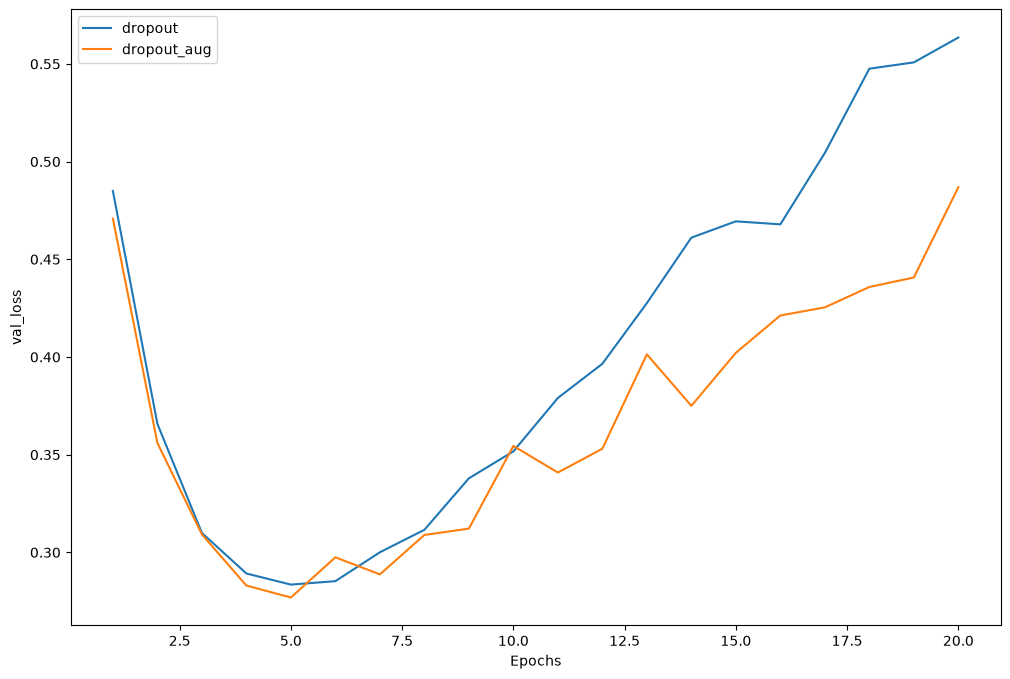

dropout: min val_loss = 0.2835 at epoch 5 | final gap = 0.4646
dropout_aug: min val_loss = 0.2769 at epoch 5 | final gap = 0.3463


In [64]:
# Question 20 :
plot_curves(histories, ["dropout", "dropout_aug"])
for name in ["dropout", "dropout_aug"]:
    ep, val = best_epoch(histories[name])
    gap = histories[name]["val_loss"][-1] - histories[name]["loss"][-1]  # final gap between validation and training loss
    print(f"{name}: min val_loss = {val:.4f} at epoch {ep} | final gap = {gap:.4f}")

We see that both models reach their minimum validation loss at the same epoch (5), with almost the same value (0.2835 for dropout vs 0.2769 for dropout_aug) : data augmentation does not really improve the best score. However, it clearly slows down overfitting : after the minimum, the validation loss of dropout_aug rises more slowly and ends at 0.49, against 0.56 for dropout. The final gap between validation and training loss goes from 0.4646 to 0.3463 (around 25% smaller), and the training accuracy stops at 0.95 instead of 0.97 : since the model sees slightly different versions of the reviews at every epoch, it memorizes the training set less.

We should note that the training loss of dropout_aug is computed on augmented (damaged) reviews, which makes it a bit higher by construction : part of the smaller gap comes from this.

We can then conclude that :
- Data augmentation is useful here as a complement to dropout : it does not improve the best model, but makes the model more robust to a long training.
- It is especially relevant when the data lacks diversity, which is not really the case with 25,000 reviews : its effect stays moderate.

### 7 - Bonus question, Early stopping

In [46]:
# Question 21 :
es_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
    ])
es_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])

# the callback checks val_loss at the end of every epoch and stops training after 3 epochs without improvement
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history_es = es_model.fit(x_train, y_train, epochs=50, batch_size=512,
                          validation_data=(x_test, y_test), callbacks=[early_stopping])
histories["early_stopping"] = history_es.history
pickle.dump(histories, open("histories.pkl", "wb"))

print(f"Number of epochs actually run : {len(history_es.history['val_loss'])}")
print(f"Best validation loss : {min(history_es.history['val_loss']):.4f}")

Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - acc: 0.8119 - loss: 0.4931 - val_acc: 0.8749 - val_loss: 0.3691
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.8995 - loss: 0.2906 - val_acc: 0.8884 - val_loss: 0.2964
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9203 - loss: 0.2239 - val_acc: 0.8897 - val_loss: 0.2800
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9324 - loss: 0.1906 - val_acc: 0.8866 - val_loss: 0.2881
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9427 - loss: 0.1664 - val_acc: 0.8822 - val_loss: 0.2984
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9482 - loss: 0.1492 - val_acc: 0.8764 - val_loss: 0.3276
Number of epochs actually run : 6
Best validation loss : 0.2800


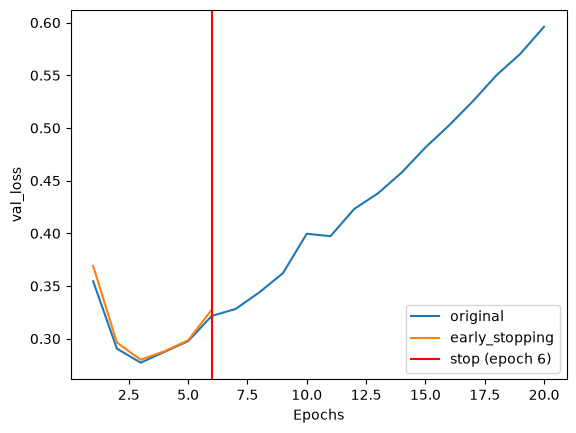

In [49]:
# Question 22
stop_epoch = len(histories["early_stopping"]["val_loss"])
for name in ["original", "early_stopping"]:
    values = histories[name]["val_loss"]
    plt.plot(range(1, len(values) + 1), values, label=name)
plt.axvline(stop_epoch, label=f"stop (epoch {stop_epoch})", color="red")
plt.xlabel("Epochs")
plt.ylabel("val_loss")
plt.legend()
plt.show()

We see that early stopping stopped the training at epoch 6 instead of 50 : the best validation loss (0.2800) was reached at epoch 3, and the 3 following epochs did not improve it (patience = 3). Its curve follows the curve of original until the stop : the minimum is almost the same (0.2800 vs 0.2772, the small difference comes from the random initialization), but the training stops right after the beginning of overfitting, while original keeps overfitting until epoch 20 (validation loss of 0.60).

The restore_best_weights parameter makes the model go back to the weights of its best epoch (epoch 3 here) when the training stops. Without it, the model would keep the weights of the last epoch (epoch 6), which already include 3 epochs of overfitting (validation loss of 0.3276 instead of 0.2800).

### 8 - Summary

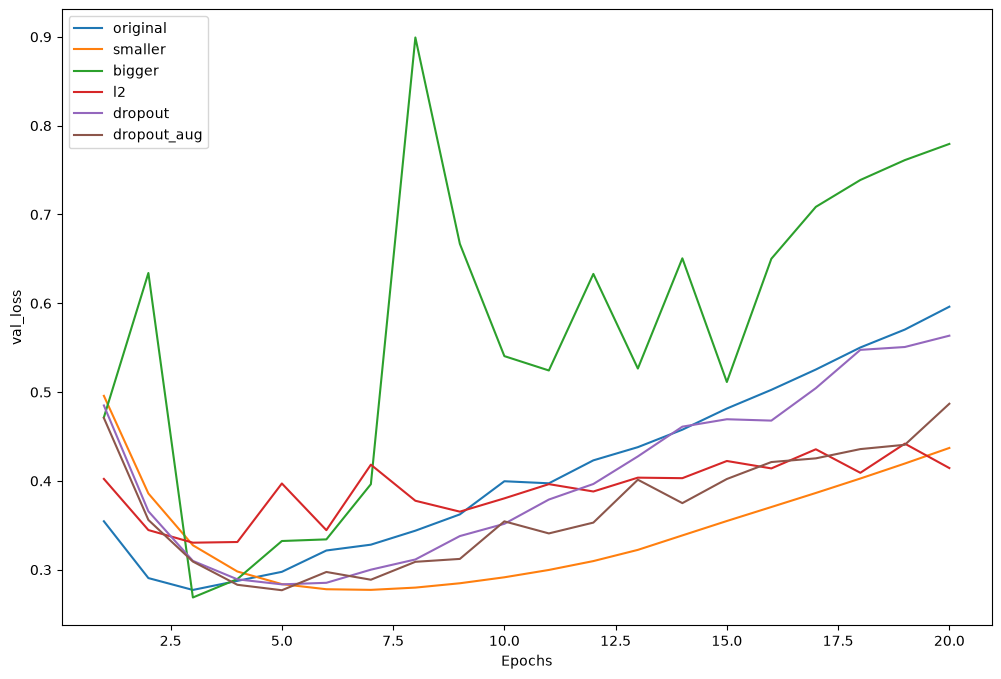

,model,best val_loss,best epoch,final val_loss
2,bigger,0.2687,3,0.7794
5,dropout_aug,0.2769,5,0.4869
0,original,0.2772,3,0.5962
1,smaller,0.2773,7,0.4371
4,dropout,0.2835,5,0.5635
3,l2,0.3304,3,0.4145


In [65]:
models_to_compare = ["original", "smaller", "bigger", "l2", "dropout", "dropout_aug"]
plot_curves(histories, models_to_compare)

summary = []
for name in models_to_compare:
    ep, val = best_epoch(histories[name])
    final = histories[name]["val_loss"][-1]  # the final value shows how robust the model is to a long training
    summary.append((name, round(val, 4), ep, round(final, 4)))
summary_df = pd.DataFrame(summary, columns=["model", "best val_loss", "best epoch", "final val_loss"])
summary_df.sort_values("best val_loss")

We see that all the models reach almost the same best validation loss (between 0.269 for bigger and 0.284 for dropout), except l2 (0.33), whose loss includes the penalty term.

Ranking by final validation loss (robustness to a long training) :
1. l2 : 0.41
2. smaller : around 0.44
3. dropout_aug : 0.49
4. dropout : 0.56
5. original : 0.60
6. bigger : 0.78

We can then conclude that :
- Capacity drives overfitting : bigger memorizes the training set almost perfectly and overfits the most, while smaller overfits later and more slowly.
- L2 is the most effective technique here : with the same number of parameters as original, it reduces the effective capacity and gives the most stable validation loss.
- Dropout alone mostly delays overfitting, and data augmentation adds a moderate gain on top of it.
- Early stopping gives the best compromise in practice : it keeps the best score of original (0.2800) and stops before overfitting, so it should be combined with the other techniques.

# Part 2 - Regression : Boston Housing (K-Fold cross-validation)

### 9 - Loading the data

In [24]:
# Question 1 : 
(b_train_data, b_train_targets), (b_test_data, b_test_targets) = boston_housing.load_data()
print(f"Train set shape: {b_train_data.shape}, Test set shape : {b_test_data.shape}")
# house price is noted in k$ according to the documentation : we need to multiply the target values by 1000 to get the price in dollars
print(f"Price (target) stats :\n10 values sample : {b_train_targets[:10]} \nMin : {b_train_targets.min()*1000}$\nMax : {b_train_targets.max()*1000}$\nMean : {b_train_targets.mean()*1000:.2f}$")

Train set shape: (404, 13), Test set shape : (102, 13)
Price (target) stats :
10 values sample : [15.2 42.3 50.  21.1 17.7 18.5 11.3 15.6 15.6 14.4] 
Min : 5000.0$
Max : 50000.0$
Mean : 22395.05$


### 10 - Data normalization

In [25]:
# Question 2 :
mean = b_train_data.mean(axis=0)
std = b_train_data.std(axis=0)
b_train_data -= mean
b_train_data /= std
b_test_data -= mean
b_test_data /= std

# The statistics should not be computed on the test set, because it is supposed to be unseen data. 
# We should only use the training set to compute the statistics in order to avoid "data leakage" (i.e. accessing informations from the test set that should not normally be known).

### 11 - Model definition

In [26]:
# Question 3 : 
def build_model():
    model = keras.Sequential([
        keras.Input(shape=(b_train_data.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    return model

# Loss is addressed to the optimization process, while metrics are used to evaluate the performance of the model.
# This is why using mse is a good choice : its derivative is easy to compute, it amplifies errors, which makes it easier to optimize.
# MAE is easier to interpret : it is the average error in the same unit as the target (k$).

### 12 - K-Fold cross-validation (K=4, 100 epochs)

In [28]:
# Question 4 : 
k = 4
num_val_samples = len(b_train_data) // k
num_epochs = 100
all_scores = []
for i in range(k):
    slice_start = i * num_val_samples
    slice_end = (i + 1) * num_val_samples
    print(f"processing fold #{i} (validation slice from {slice_start} to {slice_end})")
    val_data = b_train_data[slice_start:slice_end]
    val_targets = b_train_targets[slice_start:slice_end]
    partial_train_data = np.concatenate(
        [b_train_data[:slice_start], b_train_data[slice_end:]], axis=0) # concat of what is before the validation slice and what is after the validation slice
    partial_train_targets = np.concatenate([b_train_targets[:slice_start], b_train_targets[slice_end:]], axis=0) # same thing for targets
    model = build_model()
    model.fit(partial_train_data, partial_train_targets, epochs=num_epochs, batch_size=1, verbose=0)
    val_mse, val_mae = model.evaluate(val_data, val_targets, verbose=0)
    all_scores.append(val_mae)

pickle.dump(all_scores, open("boston_q4_scores.pkl", "wb"))

# Question 5 : 
print(f"All scores : {all_scores}")
print(f"Mean score : {np.mean(all_scores)}\nStandard deviation : {np.std(all_scores)}")
# The average MAE being 2.9, it means that the model is off by 2.900$ on average when predicting house prices, which is a reasonable given the average price of houses in the dataset is 22.500$.

processing fold #0 (validation slice from 0 to 101)
processing fold #1 (validation slice from 101 to 202)
processing fold #2 (validation slice from 202 to 303)
processing fold #3 (validation slice from 303 to 404)
All scores : [2.579690456390381, 3.0471532344818115, 3.2198550701141357, 3.092913866043091]
Mean score : 2.9849031567573547
Standard deviation : 0.24235362573407893


### 13 - Tracking validation MAE per epoch (500 epochs)

In [29]:
num_epochs = 500

In [30]:
# Question 6 : 
k = 4
num_val_samples = len(b_train_data) // k
all_mae_histories = []
for i in range(k):
    slice_start = i * num_val_samples
    slice_end = (i + 1) * num_val_samples
    print(f"processing fold #{i} (validation slice from {slice_start} to {slice_end})")
    val_data = b_train_data[slice_start:slice_end]
    val_targets = b_train_targets[slice_start:slice_end]
    partial_train_data = np.concatenate(
        [b_train_data[: slice_start], b_train_data[slice_end:]], axis=0) # concat of what is before the validation slice and what is after the validation slice
    partial_train_targets = np.concatenate(
        [b_train_targets[: slice_start], b_train_targets[slice_end:]], axis=0) # same thing for targets
    model = build_model()
    history = model.fit(partial_train_data, partial_train_targets,
                        validation_data=(val_data, val_targets),
                        epochs=num_epochs, batch_size=1, verbose=0)
    all_mae_histories.append(history.history["val_mae"]) 

pickle.dump(all_mae_histories, open("boston_q6_histories.pkl", "wb"))
print(np.array(all_mae_histories).shape)  # we expect (4, 500)


processing fold #0 (validation slice from 0 to 101)
processing fold #1 (validation slice from 101 to 202)
processing fold #2 (validation slice from 202 to 303)
processing fold #3 (validation slice from 303 to 404)
(4, 500)


In [31]:
#all_mae_histories = pickle.load(open("boston_q6_histories.pkl", "rb")) 

# Question 7 :

average_mae_history = [np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)]
ep, val = best_epoch({"val_mae": average_mae_history}, key="val_mae")
print(f"final average mae (epoch {num_epochs}): {average_mae_history[-1]:.3f}")
print(f"best average mae: {val:.3f} at epoch {ep}")

final average mae (epoch 500): 3.193
best average mae: 2.520 at epoch 38


### 14 - Visualization

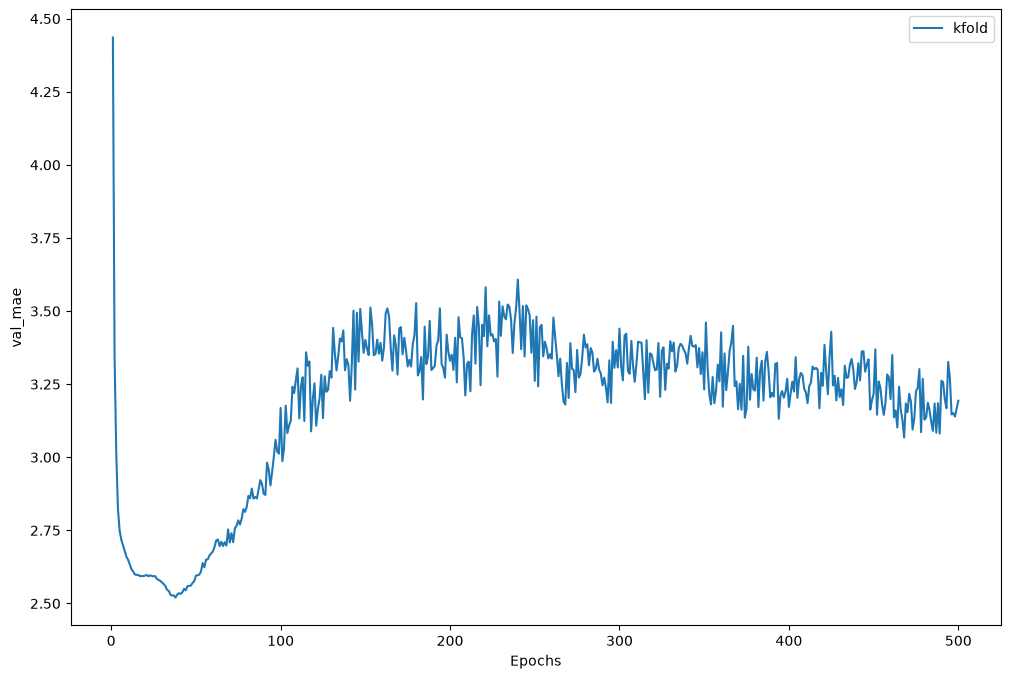

In [32]:
# Question 8 :
plot_curves({"kfold": {"val_mae": average_mae_history}}, ["kfold"], key="val_mae")

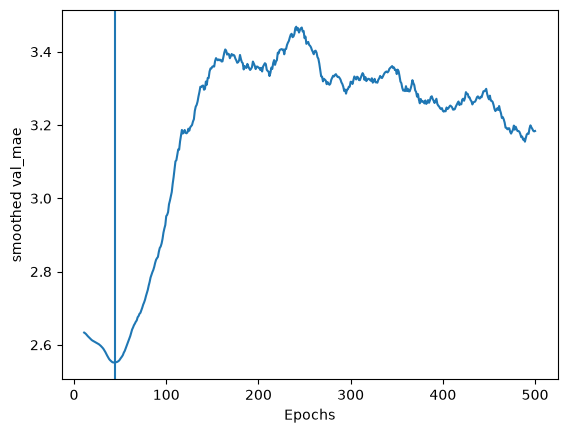

smoothed minimum: 2.551 at epoch 44


In [33]:
# Question 9 : 
def smooth_curve(points, factor=0.9):
    smoothed_points = []
    for point in points:
        if smoothed_points:  # a non-empty list is true in python
            previous = smoothed_points[-1]
            smoothed_points.append(factor * previous + (1 - factor) * point)
        else:
            smoothed_points.append(point)  # the first point is kept as it is
    return smoothed_points

smoothed = smooth_curve(average_mae_history[10:])
epochs = range(11, 11 + len(smoothed))  # index 0 of smoothed is epoch 11, since we dropped the first 10
best_ep = int(np.argmin(smoothed)) + 11
plt.plot(epochs, smoothed)
plt.axvline(best_ep)
plt.xlabel("Epochs")
plt.ylabel("smoothed val_mae")
plt.show()
print(f"smoothed minimum: {min(smoothed):.3f} at epoch {best_ep}")

### 15 - Final Model

In [34]:
# Question 10 : 
final_model = build_model()  # a fresh model, trained on all the training examples this time
final_model.fit(b_train_data, b_train_targets, epochs=best_ep, batch_size=16, verbose=0)
test_mse, test_mae = final_model.evaluate(b_test_data, b_test_targets, verbose=0)
print(f"Test mse: {test_mse:.5f}\nTest mae: {test_mae:.5f}")
print(f"average error on the predicted price: {test_mae * 1000:.2f}$")

Test mse: 18.44701
Test mae: 2.99829
average error on the predicted price: 2998.29$


Question 11

| Technique | Principle | When to use it |
|---|---|---|
| Reduce model size | Fewer parameters => less memorization | First thing to try if overfitting |
| L1 regularization | Penalizes \|w\|, creates sparsity | Feature selection |
| L2 regularization | Penalizes w^2, keeps weights small | Default technique |
| Dropout | Randomly deactivates neurons | Very effective for dense layers |
| Data augmentation | Creates variants of the examples | When data lacks diversity |
| Early Stopping | Stops training before overfitting | Always recommended in practice |
| K-Fold Cross Validation | Robust evaluation on small datasets | Small datasets |
| More data | The best regularization, when it is possible! | When it is possible |

# Part 3 - Comparing optimization algorithms

### 17 - Loading and normalizing the data

In [35]:
# Question 1 : 
(b_train_data, b_train_targets), (b_test_data, b_test_targets) = boston_housing.load_data()
print(f"Train set shape: {b_train_data.shape}, Test set shape : {b_test_data.shape}")
# house price is noted in k$ according to the documentation : we need to multiply the target values by 1000 to get the price in dollars
print(f"Price (target) stats :\n10 values sample : {b_train_targets[:10]} \nMin : {b_train_targets.min()*1000}$\nMax : {b_train_targets.max()*1000}$\nMean : {b_train_targets.mean()*1000:.2f}$")

Train set shape: (404, 13), Test set shape : (102, 13)
Price (target) stats :
10 values sample : [15.2 42.3 50.  21.1 17.7 18.5 11.3 15.6 15.6 14.4] 
Min : 5000.0$
Max : 50000.0$
Mean : 22395.05$


In [36]:
mean = b_train_data.mean(axis=0)
std = b_train_data.std(axis=0)
b_train_data -= mean
b_train_data /= std
b_test_data -= mean
b_test_data /= std

### 18 - Model parameterized by the optimizer

In [37]:
# Question 2 : 
def build_model(input_dim, optimizer='adam'):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
    return model

### 19 - Generic cross-validation

In [38]:
# Question 3
def run_kfold_for_optimizer(optimizer_name, x_train, y_train, k=4, num_epochs=200, batch_size=16):
    num_val_samples = len(x_train) // k
    all_mae_histories = []
    fold_scores = []
    for i in range(k):
        slice_start = i * num_val_samples
        slice_end = (i + 1) * num_val_samples
        val_data = x_train[slice_start:slice_end]
        val_targets = y_train[slice_start:slice_end]
        partial_train_data = np.concatenate([x_train[:slice_start], x_train[slice_end:]], axis=0)
        partial_train_targets = np.concatenate([y_train[:slice_start], y_train[slice_end:]], axis=0)
        model = build_model(x_train.shape[1], optimizer=optimizer_name)  # a fresh model and a fresh optimizer for each fold
        history = model.fit(partial_train_data, partial_train_targets,
                            validation_data=(val_data, val_targets),
                            epochs=num_epochs, batch_size=batch_size, verbose=0)
        all_mae_histories.append(history.history["val_mae"])
        fold_scores.append(history.history["val_mae"][-1])  # the score of a fold is its validation mae at the last epoch
    return {"optimizer": optimizer_name,
            "fold_scores": fold_scores,
            "avg_mae_history": np.mean(np.array(all_mae_histories), axis=0)}

In [39]:
# Question 4
opt_results = {}
for optimizer_name in ["sgd", "adagrad", "rmsprop", "adam"]:
    print(f"running k-fold for optimizer {optimizer_name}")
    opt_results[optimizer_name] = run_kfold_for_optimizer(optimizer_name, b_train_data, b_train_targets,
                                                          k=4, num_epochs=200, batch_size=16)
    pickle.dump(opt_results, open("opt_results.pkl", "wb"))  # we save after each optimizer, in case of a crash

running k-fold for optimizer sgd
running k-fold for optimizer adagrad
running k-fold for optimizer rmsprop
running k-fold for optimizer adam


### 20 - Comparing the optimizers

In [41]:
# Question 5
for name, r in opt_results.items():
    scores = r["fold_scores"]
    print(f"{name}: folds = {np.round(scores, 3)} | mean = {np.mean(scores):.3f} | std = {np.std(scores):.3f}")

sgd: folds = [2.028 2.014 2.47  2.587] | mean = 2.275 | std = 0.257
adagrad: folds = [3.773 5.34  3.806 5.809] | mean = 4.682 | std = 0.908
rmsprop: folds = [1.963 2.296 2.586 2.469] | mean = 2.328 | std = 0.235
adam: folds = [2.187 2.544 2.36  2.356] | mean = 2.362 | std = 0.126


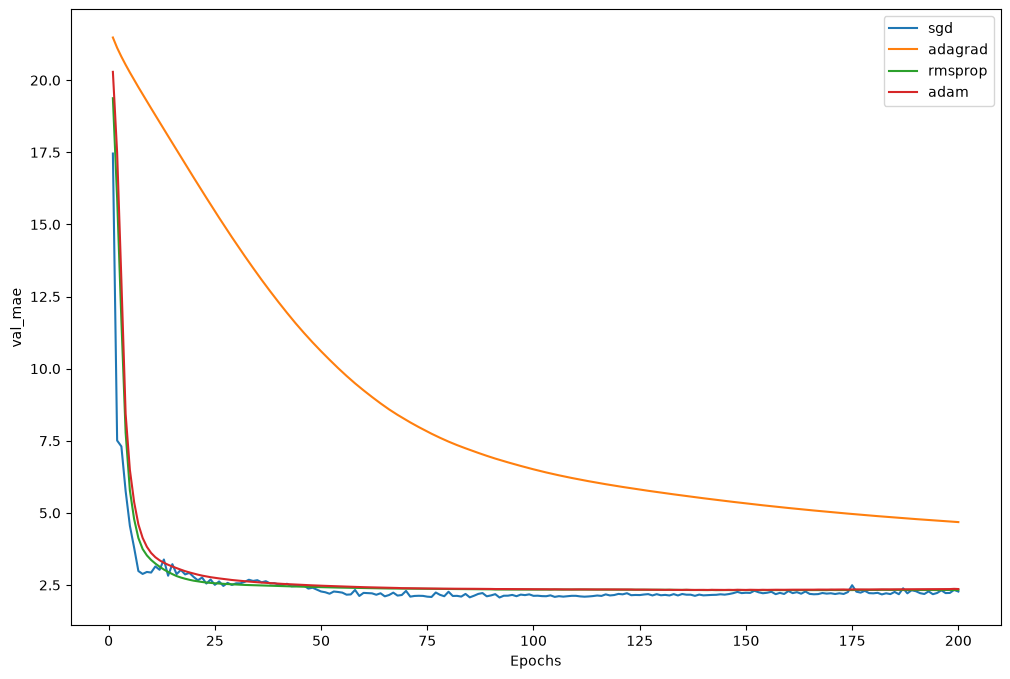

In [42]:
# Question 6
# we reshape opt_results into the format expected by plot_curves, so that we can reuse it
opt_histories = {name: {"val_mae": r["avg_mae_history"]} for name, r in opt_results.items()}
plot_curves(opt_histories, list(opt_histories), key="val_mae")

sgd: smoothed min mae = 2.121 at epoch 114
adagrad: smoothed min mae = 4.781 at epoch 200
rmsprop: smoothed min mae = 2.327 at epoch 169
adam: smoothed min mae = 2.334 at epoch 153


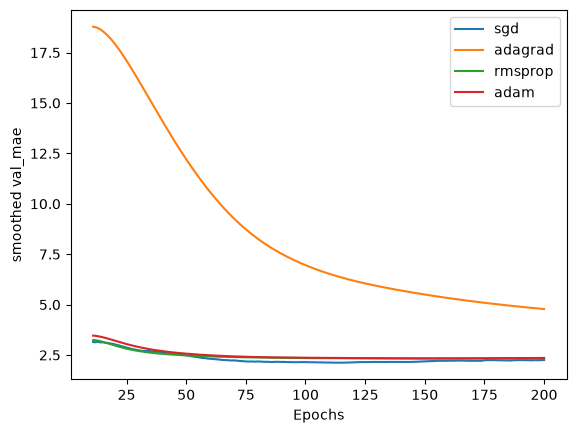

In [43]:
# Question 7
best_epochs = {}
for name, r in opt_results.items():
    smoothed = smooth_curve(r["avg_mae_history"][10:])
    best_ep = int(np.argmin(smoothed)) + 11  # index 0 of smoothed is epoch 11
    best_epochs[name] = best_ep
    plt.plot(range(11, 11 + len(smoothed)), smoothed, label=name)
    print(f"{name}: smoothed min mae = {min(smoothed):.3f} at epoch {best_ep}")
plt.xlabel("Epochs")
plt.ylabel("smoothed val_mae")
plt.legend()
plt.show()

### 21 - Final model and ranking

In [44]:
# Question 8
test_results = {}
for name in opt_results:
    model = build_model(b_train_data.shape[1], optimizer=name)  # a fresh model and a fresh optimizer
    model.fit(b_train_data, b_train_targets, epochs=best_epochs[name], batch_size=16, verbose=0)
    test_mse, test_mae = model.evaluate(b_test_data, b_test_targets, verbose=0)
    test_results[name] = (test_mse, test_mae)
    print(f"{name}: test mse = {test_mse:.3f} | test mae = {test_mae:.3f} ({test_mae * 1000:.0f}$)")
pickle.dump(test_results, open("opt_test_results.pkl", "wb"))

sgd: test mse = 13.621 | test mae = 2.634 (2634$)
adagrad: test mse = 36.040 | test mae = 4.686 (4686$)
rmsprop: test mse = 14.228 | test mae = 2.683 (2683$)
adam: test mse = 14.873 | test mae = 2.473 (2473$)


In [45]:
# Question 9
ranking = sorted(test_results, key=lambda name: test_results[name][1])  # we sort by test mae, from best to worst
for rank, name in enumerate(ranking, start=1):
    print(f"{rank}. {name}: test mae = {test_results[name][1]:.3f}")

1. adam: test mae = 2.473
2. sgd: test mae = 2.634
3. rmsprop: test mae = 2.683
4. adagrad: test mae = 4.686


Ranking (test MAE, from best to worst) :
1. adam : 2.473 (2473$)
2. sgd : 2.634 (2634$)
3. rmsprop : 2.683 (2683$)
4. adagrad : 4.686 (4686$)

We see that RMSprop and Adam converge the fastest : their validation MAE is already close to its plateau around epoch 25, with very smooth curves. SGD converges almost as fast, but its curve is much noisier, since its step size does not adapt. Adagrad is by far the slowest : its smoothed minimum is reached at the very last epoch (200), which means it has not converged yet. This comes from its learning rate, which is divided by the square root of the sum of all past squared gradients : this sum only grows, so the steps keep shrinking.

On this test set, Adam generalizes best. However, the differences between adam, sgd and rmsprop (0.2 at most) are of the same order as the standard deviations between folds (0.13 to 0.26), and the ranking changes with the criterion : sgd was the best during the k-fold (smoothed minimum of 2.121) and has the lowest test MSE (13.621), which means it makes fewer large errors. Each final model is trained only once and evaluated on 102 houses only.

We can then conclude that :
- adam, sgd and rmsprop are practically equivalent on this dataset, with adam slightly ahead on the test MAE.
- adagrad is clearly behind, because it did not converge within 200 epochs.